In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
chain_path = Path("/global/u1/z/zhaozhon/project/results/mcmc/per_bin/order1_all/y3_bin1_z2.3-2.4_all_order1_w10000_s10000_c4.npz")
obs_path   = Path("/global/u1/z/zhaozhon/project/data/processed/y3_bin1_z2.3-2.4_arrays.npz")

assert chain_path.exists(), chain_path
assert obs_path.exists(), obs_path

In [3]:
chain_data = np.load(chain_path, allow_pickle=True)
obs_data   = np.load(obs_path, allow_pickle=True)

print("=== CHAIN KEYS ===")
for k in chain_data.files:
    arr = chain_data[k]
    print(f"{k:25s} shape={arr.shape} dtype={arr.dtype}")

=== CHAIN KEYS ===
alpha                     shape=(40000,) dtype=float64
b                         shape=(40000,) dtype=float64
beta                      shape=(40000,) dtype=float64
gap                       shape=(40000,) dtype=float64
log_Lstar                 shape=(40000,) dtype=float64
log_Nphi                  shape=(40000,) dtype=float64
m0                        shape=(40000,) dtype=float64
bin_index                 shape=() dtype=int64
case                      shape=() dtype=<U3
order                     shape=() dtype=int64
zmin                      shape=() dtype=float64
zmax                      shape=() dtype=float64
N                         shape=() dtype=int64
sigma_coeff               shape=(2,) dtype=float64
m_ref                     shape=() dtype=float64
sigma_fit_nbins           shape=() dtype=int64
sigma_fit_min_per_bin     shape=() dtype=int64
input_arrays              shape=() dtype=<U75


In [12]:
def flatten_samples(x):
    return np.asarray(x).reshape(-1)

def get_first_existing(data, candidates):
    for k in candidates:
        if k in data.files:
            return flatten_samples(data[k]), k
    raise KeyError(f"None of these keys found: {candidates}")

def sigmoid_eff(m, m0, b):
    return 1.0 / (1.0 + np.exp(b * (m - m0)))

def Mstar_from_logLstar(log_Lstar):
    # log_Lstar is natural log of internal L*
    return -(2.5 / np.log(10.0)) * log_Lstar

def phi_M(M, log_Nphi, log_Lstar, alpha, beta):
    """
    Intrinsic double-power-law QLF in magnitude space.
    """
    phi_star = np.exp(log_Nphi)
    M_star = np.median(M_obs)  

    x = M - M_star
    term1 = 10.0 ** (-0.4 * (alpha + 1.0) * x)
    term2 = 10.0 ** (-0.4 * (beta  + 1.0) * x)
    return phi_star / (term1 + term2)

def observed_model_M(M, mu_mean, k_mean, log_Nphi, log_Lstar, alpha, beta, m0, b):
    """
    Approx observed model:
        observed ~ intrinsic QLF * selection(m)
    with m = M + mu_mean + k_mean
    """
    m = M + mu_mean + k_mean
    phi = phi_M(M, log_Nphi, log_Lstar, alpha, beta)
    eff = sigmoid_eff(m, m0, b)
    return phi * eff, eff, m

In [13]:
log_Nphi, key_log_Nphi = get_first_existing(
    chain_data, ["log_Nphi", "log_phi", "log_phi0", "ln_phi", "lnNphi"]
)
log_Lstar, key_log_Lstar = get_first_existing(
    chain_data, ["log_Lstar", "log_L0", "logLstar", "lnLstar", "ln_Lstar"]
)
alpha, key_alpha = get_first_existing(chain_data, ["alpha"])
beta, key_beta = get_first_existing(chain_data, ["beta"])
m0, key_m0 = get_first_existing(chain_data, ["m0"])
b, key_b = get_first_existing(chain_data, ["b"])

print("Using chain keys:")
print(" log_Nphi  <-", key_log_Nphi)
print(" log_Lstar <-", key_log_Lstar)
print(" alpha     <-", key_alpha)
print(" beta      <-", key_beta)
print(" m0        <-", key_m0)
print(" b         <-", key_b)
print("n samples  =", len(alpha))

Using chain keys:
 log_Nphi  <- log_Nphi
 log_Lstar <- log_Lstar
 alpha     <- alpha
 beta      <- beta
 m0        <- m0
 b         <- b
n samples  = 40000


In [14]:
def summarize(x, name):
    q16, q50, q84 = np.percentile(x, [16, 50, 84])
    print(f"{name:10s}: {q50:.6f}  (-{q50-q16:.6f}, +{q84-q50:.6f})")
    return q50

fit = {
    "log_Nphi": summarize(log_Nphi, "log_Nphi"),
    "log_Lstar": summarize(log_Lstar, "log_Lstar"),
    "alpha": summarize(alpha, "alpha"),
    "beta": summarize(beta, "beta"),
    "m0": summarize(m0, "m0"),
    "b": summarize(b, "b"),
}

print("Derived M* =", Mstar_from_logLstar(fit["log_Lstar"]))

log_Nphi  : 8.598871  (-0.306921, +0.248692)
log_Lstar : 24.670411  (-0.189116, +0.213795)
alpha     : -1.569014  (-0.141643, +0.127667)
beta      : -3.324823  (-0.155260, +0.128591)
m0        : 22.427571  (-0.314147, +0.272840)
b         : 1.548561  (-0.109009, +0.176646)
Derived M* = -26.785557884604557


In [15]:
m_obs = np.asarray(obs_data["apr_mag_r"])
k_obs = np.asarray(obs_data["k"])
mu_obs = np.asarray(obs_data["mu"])

z_center = float(np.asarray(obs_data["z_center"]).reshape(-1)[0])
zmin = float(np.asarray(obs_data["zmin"]).reshape(-1)[0])
zmax = float(np.asarray(obs_data["zmax"]).reshape(-1)[0])

M_obs = m_obs - mu_obs - k_obs

mask = np.isfinite(M_obs) & np.isfinite(m_obs) & np.isfinite(k_obs) & np.isfinite(mu_obs)
M_obs = M_obs[mask]
m_obs = m_obs[mask]
k_obs = k_obs[mask]
mu_obs = mu_obs[mask]

print("N objects =", len(M_obs))
print("M range   =", np.min(M_obs), np.max(M_obs))
print("m range   =", np.min(m_obs), np.max(m_obs))
print("k mean    =", np.mean(k_obs))
print("mu mean   =", np.mean(mu_obs))

N objects = 33604
M range   = -29.33005574896782 -22.338027520728055
m range   = 16.823678970336914 22.999814987182617
k mean    = -0.24462700479357702
mu mean   = 46.43528403530143


In [16]:
mu_mean = float(np.mean(mu_obs))
k_mean = float(np.mean(k_obs))

print("z bin     =", zmin, zmax)
print("z_center  =", z_center)
print("mu_mean   =", mu_mean)
print("k_mean    =", k_mean)

z bin     = 2.3 2.4
z_center  = 2.3499999999999996
mu_mean   = 46.43528403530143
k_mean    = -0.24462700479357702


In [17]:
M_min = np.min(M_obs) - 0.5
M_max = np.max(M_obs) + 0.5
M_grid = np.linspace(M_min, M_max, 500)

phi_intrinsic = phi_M(
    M_grid,
    fit["log_Nphi"],
    fit["log_Lstar"],
    fit["alpha"],
    fit["beta"],
)

phi_obs_model, eff_grid, m_grid = observed_model_M(
    M_grid,
    mu_mean=mu_mean,
    k_mean=k_mean,
    log_Nphi=fit["log_Nphi"],
    log_Lstar=fit["log_Lstar"],
    alpha=fit["alpha"],
    beta=fit["beta"],
    m0=fit["m0"],
    b=fit["b"],
)

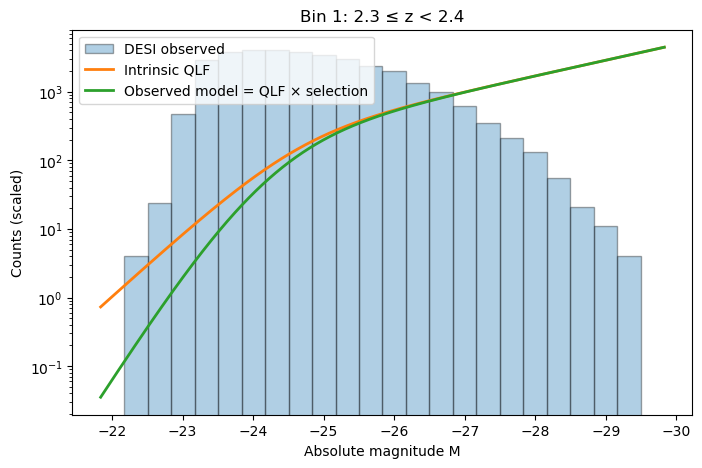

In [18]:
bins = np.linspace(M_min, M_max, 25)
hist_counts, edges = np.histogram(M_obs, bins=bins)
centers = 0.5 * (edges[:-1] + edges[1:])

phi_intrinsic_centers = phi_M(
    centers,
    fit["log_Nphi"],
    fit["log_Lstar"],
    fit["alpha"],
    fit["beta"],
)

phi_obs_centers, _, _ = observed_model_M(
    centers,
    mu_mean=mu_mean,
    k_mean=k_mean,
    log_Nphi=fit["log_Nphi"],
    log_Lstar=fit["log_Lstar"],
    alpha=fit["alpha"],
    beta=fit["beta"],
    m0=fit["m0"],
    b=fit["b"],
)

# scale curves for shape comparison only
scale_intrinsic = hist_counts.max() / np.nanmax(phi_intrinsic_centers)
scale_obs = hist_counts.max() / np.nanmax(phi_obs_centers)

plt.figure(figsize=(8, 5))
plt.hist(M_obs, bins=bins, alpha=0.35, edgecolor="black", label="DESI observed")
plt.plot(M_grid, scale_intrinsic * phi_intrinsic, lw=2, label="Intrinsic QLF")
plt.plot(M_grid, scale_obs * phi_obs_model, lw=2, label="Observed model = QLF × selection")
plt.gca().invert_xaxis()
plt.yscale("log")
plt.xlabel("Absolute magnitude M")
plt.ylabel("Counts (scaled)")
plt.title(f"Bin 1: {zmin:.1f} ≤ z < {zmax:.1f}")
plt.legend()
plt.show()